In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

(375, 450) uint8
(375, 450) uint8


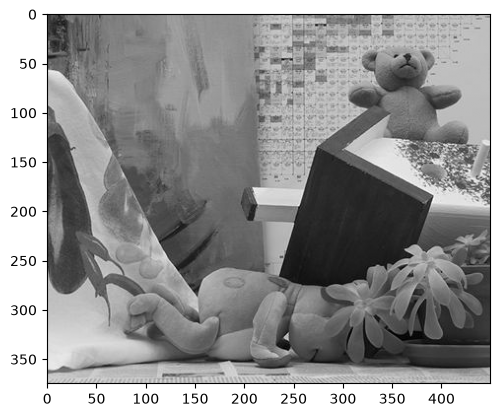

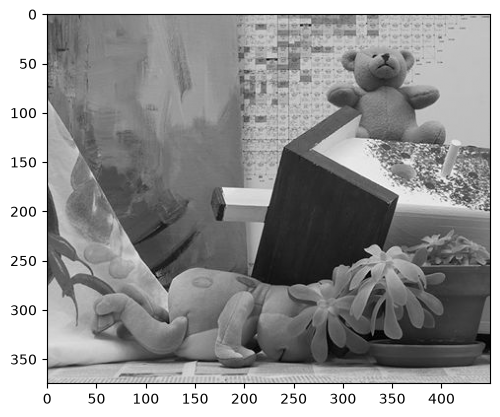

In [2]:
match_left = cv2.imread("assignment-3-data/match_left.jpg", cv2.IMREAD_GRAYSCALE)
plt.figure()
plt.imshow(match_left, cmap='gray')
print(match_left.shape, match_left.dtype)

match_right = cv2.imread("assignment-3-data/match_right.jpg", cv2.IMREAD_GRAYSCALE)
plt.figure()
plt.imshow(match_right, cmap='gray')
print(match_right.shape, match_right.dtype)

In [3]:
def find_best_match(patch, strip, match_type) :
    patch = patch.astype(np.float64)
    strip = strip.astype(np.float64)

    w = patch.shape[1]
    W = strip.shape[1]

    n_positions = W - w + 1
    scores = np.zeros(n_positions)

    for i in range(n_positions) :
        window = strip[:, i:i+w]

        if match_type == 0:  ## SSD
            scores[i] = np.sum((patch - window) **2)

        elif match_type == 1:  # NCC
            patch_zm = patch - np.mean(patch)
            window_zm = window - np.mean(window)
            scores[i] = np.sum(patch_zm * window_zm) / (np.sqrt(np.sum(patch_zm**2)) * np.sqrt(np.sum(window_zm**2)))

    if match_type == 0:  # SSD
        best_match_position = np.argmin(scores)
    elif match_type == 1:  # NCC
        best_match_position = np.argmax(scores)

    return best_match_position, scores


In [4]:
def print_click(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN:
        print(x, y)

cv2.namedWindow("left")
cv2.setMouseCallback("left", print_click)
cv2.imshow("left", match_left)
cv2.waitKey(0)
cv2.destroyAllWindows()

302 137


In [8]:
x = 302
y = 137
w = 21
h = 21

patch = match_left[y - h // 2 : y + h // 2 + 1, x - w // 2 : x + w // 2 + 1]
strip = match_right[y - h // 2 : y + h // 2 + 1, :]

best_ssd, scores_ssd = find_best_match(patch, strip, 0)
print("Best SSD match position:", best_ssd)
print("SSD match scores:", scores_ssd[best_ssd])

best_ncc, scores_ncc = find_best_match(patch, strip, 1)
print("Best NCC match position:", best_ncc)
print("NCC match scores:", scores_ncc[best_ncc])


Best SSD match position: 259
SSD match scores: 55340.0
Best NCC match position: 259
NCC match scores: 0.9672567930810384
